# Find the single points of failure in medical-device recalls with GFQL and semantic operators

When one medical-device design fails, every firm that sells it recalls it, and that design is a single point of failure in the supply chain. The US Food and Drug Administration (FDA) publishes every recall, but an analyst who asks a model about all 59,705 records pays for a model call on every one. This notebook uses a Cypher query to keep only the recalls that sit on a design that three or more firms recalled, asks a model typed questions about them with `sem_decide`, and measures what each step saves in requests, cost and time.

![Five stages: time, cost and quality](gfql_semantic_procurement_chart.png)

*The chart comes from the run below. The numbers are simulated: the notebook answers with a calibrated mock model. See "What is real and what is simulated".*

| you will see | where |
|---|---|
| Cypher, `sem_decide`, a plan and a trace in one cell | **The pipeline in one cell** |
| what is real and what is simulated | **What is real and what is simulated** |
| the data, the three questions and the simulator | **The data, the labels and the simulated model** |
| five stages with tables | **Stages 1 to 3**, **Stages 4 and 5** |
| the chart, plan against run, and a graph to plot | **The chart**, **The hub graph** |
| how to measure a live model (opt in, gated) | **Measure a live model** |

**Setup.** The first run downloads three public files (about 390 MB) into `/tmp/openfda-cache`, so it needs network access. The helper module `procurement_helpers.py` holds the download, parse, simulator, stage runners and chart code. The notebook expects it in the same folder (`demos/gfql/`): start Jupyter there, or add that folder to `sys.path`. The Appendix shows its source. Set `DEMO_LIVE=1` to use a live model (needs keys and spends money; see the end).

*Data: [openFDA](https://open.fda.gov/) device recall, device enforcement and device classification files. openFDA data is in the public domain under a [CC0 1.0](https://open.fda.gov/license/) dedication. openFDA asks you not to rely on it for decisions about medical care, and this notebook does not. This repository does not contain the data.*

In [1]:
import polars as pl

import procurement_helpers as h

h.init()    # download (once), parse, derive the labels and hubs, build the graph

from graphistry import e_reverse, n
from graphistry.compute.semantic import (
    MemorySemanticCache,
    bind_providers,
    explain_sem_decide,
    semantic_summary,
    semantic_trace,
    semantic_verdicts,
)
from procurement_helpers import (
    EVIDENCE,
    OPTIONS,
    PARALLEL,
    QUESTIONS,
    decisions_provider,
    g,
    session_for,
    show,
)

print("mode:", "LIVE model (opt in)" if h.DEMO_LIVE else "simulated model ($0, no key)")

openFDA device recalls (full download) | 59,705 recall records | 40,535 enforcement records | 7,103 product codes | read in 33 s


40,532 recalls with an FDA class | 9,474 designs | 102 hubs | 52,484 nodes | 72,798 edges
mode: simulated model ($0, no key)


## The pipeline in one cell

**Input and run:** ONE Cypher query on the Polars graph `g` keeps the recalls on a design that three or more firms recalled, then `CALL graphistry.sem_decide($sem)` asks the model about the rows that remain. The `WITH` names the columns that the model reads; `$sem` carries the questions, the evidence columns, the provider alias and the limits, so the query text stays plain. **Config:** three typed questions, a provider and a probability limit (`min_p`). **Output:** one verdict for each recall, the plan for the same rows and a trace of the run. The provider is simulated here, so the cell costs $0.

In Cypher, `(d:design)` and `[:cleared_as]` read the `type` column of the nodes and the edges. This cell leaves `dedupe` on, its default: a repeated text is asked once. The stages below pass `dedupe=False`, so that each stage asks about every row, as a plain loop does.

In [2]:
# 1. Config: typed questions, evidence columns and guardrails travel as ONE $param
provider = decisions_provider(session_for())  # simulated unless DEMO_LIVE=1
sem = dict(
    questions=QUESTIONS,
    evidence=EVIDENCE,
    provider="triage",
    task_id="recall-triage",
    id_col="recall_id",
    max_concurrency=PARALLEL,
    require_probabilities=True,
    min_p=0.85,
    **OPTIONS,  # live mode adds budget={"max_cost_usd": 0.50}
)

# 2. Run: ONE query narrows the graph, then asks the model about the rows that remain
cache = MemorySemanticCache()
with bind_providers({"triage": provider}, cache=cache), semantic_trace() as runs:
    triaged = g.gfql(
        """
        MATCH (d:design {hub: true})<-[:cleared_as]-(r:recall)
        WITH DISTINCT r.id AS recall_id,
                      r.reason_for_recall AS reason_for_recall,
                      r.device_name AS device_name
        CALL graphistry.sem_decide($sem)
        """,
        params={"sem": sem},
        engine="polars",
    )

# 3. Output: the plan for the same rows (no request), status counts, verdicts, the trace
rows = triaged._nodes.to_pandas()
plan = h.plan_of(rows, provider, sem)
verdict = semantic_verdicts(rows, "fda_class", positive="class_I")
show(semantic_summary(rows))
show(verdict.value_counts().rename("recalls").to_frame().T)
print(
    f"plan: {plan['planned_calls']:,} calls for {plan['active_rows']:,} recalls, "
    f"dedupe saves {plan['dedupe_saved_rows']:,} | "
    f"run: {runs[0]['provider_calls']:,} calls, billed ${runs[0]['billed_cost_usd']:.2f}"
)


*SIMULATED model on real openFDA device recalls*

,ok,uncertain,error,skipped,unanswered,unanswered_pct
question,,,,,,
supplier_related,1193,112,0,0,112,8.58
root_cause_family,1164,141,0,0,141,10.80
fda_class,1160,145,0,0,145,11.11


*SIMULATED model on real openFDA device recalls*

,no,uncertain,yes,error,skipped
recalls,1095,145,65,0,0


plan: 595 calls for 1,305 recalls, dedupe saves 710 | run: 595 calls, billed $0.60


In [3]:
# The same query as a GFQL chain (Python objects), on the Polars engine
hub_chain = [
    n({"type": "design", "hub": True}),
    e_reverse({"type": "cleared_as"}),
    n({"type": "recall"}, name="member"),
]
chain_ids = g.gfql(hub_chain, engine="polars")._nodes.filter(pl.col("member"))["id"]
hero_ids = set(triaged._nodes["recall_id"])
assert set(chain_ids) == hero_ids, "Cypher and the chain must agree"
print(f"{len(chain_ids):,} recalls from the chain: the same rows as the Cypher query")

1,305 recalls from the chain: the same rows as the Cypher query


`yes` is a recall that the model calls Class I with a probability of at least 0.85. `uncertain` goes to a review queue. An `error` or `skipped` row is never counted as `no`. The rest of the notebook builds this cell up in five stages and measures each one.

## What is real and what is simulated

The recalls, the designs, the firms, the FDA classes and the GFQL queries are **real**. The default run sends **no request to a model**, uses **no API key** and costs **$0**. A *simulated* model answers the questions. Its cost, time and accuracy come from stated assumptions, not from a live benchmark. Every result table and chart says "simulated". Set `DEMO_LIVE=1` to measure a live model (see the end). The notebook needs a version of GraphistryPy that has `dedupe`, `SemanticCache`, `explain_sem_decide`, `semantic_trace` and `semantic_verdicts`.

**The labels are the FDA's, not mine.** The root cause and the class (Class I, II or III) of a recall are FDA fields. The prompts never contain them. Two limits follow:

- About a quarter of the recalls have a root cause of `Other`, `Under investigation` or `Unknown`, so no model can read it from the text.
- Recalls with the **same text** can carry **different** FDA labels (the notebook counts the prompts where they do). The simulated model gives the same answer to the same text, and the notebook scores it against the label of each recall.

**The simulator does not obey the first limit.** It corrupts the most common FDA label of each text, so it effectively knows the label, even when the root cause is `Under investigation`. Its accuracy is therefore an upper bound that a real model cannot reach.

## The data, the labels and the simulated model

**Files.** openFDA publishes each file as one zip of pretty-printed JSON. The recall file holds 59,705 records and is 1.5 GB unpacked, so the helper module **streams** it: it reads one record at a time and keeps only the fields that it needs. A download goes to a temporary name first, so a stopped download never leaves a broken file. The notebook commits no dataset file. openFDA replaces its files every week, so the notebook checks the SHA-256 of each file and prints a note when it is not the file that the committed outputs come from (the numbers then differ).

- recall file: one record for each recalled product, with the free-text reason, the FDA root cause, the firm and the 510(k) numbers
- enforcement file: the FDA class of each recall (`recall_number` is the `product_res_number` of the recall file)
- classification file: the device name of each product code

The notebook keeps the recalls that have an FDA class (about two thirds). The model reads **two** fields of a recall: the free-text `reason_for_recall` and the `device_name`. The firm, the product description, the root cause, the class and the 510(k) numbers are **not** in the prompt. A fixed table groups the forty FDA root causes into six families:

| family | FDA root causes |
|---|---|
| `component_or_supplier` | material or component problems, component design or change control, vendor change control, counterfeit |
| `design` | device design, process design |
| `manufacturing_process` | process control or change, employee error, equipment, environment, storage, reprocessing |
| `software` | every software root cause |
| `packaging_labeling` | packaging and labeling root causes, expiration date |
| `other_or_unknown` | other, under investigation, unknown, pending, no marketing application, PMA, radiation control, use error, and a missing value |

**Hubs.** Each recall can name one or more 510(k) numbers, and a 510(k) number identifies a cleared **design**. The graph has three node types (`recall`, `firm`, `design`) and two edge types (`recalled`: firm to recall, `cleared_as`: recall to design). A **hub** is a design that **three or more different firms** recalled: one flaw reaches all those firms. The number 3 is a choice. The same company recalls under many spellings (`Maquet Cardiovascular US Sales, LLC` and `Maquet Cardiovascular, LLC`), so the notebook merges names by their first two significant words (it drops `LLC`, `Inc`, `Medical`, `Sales` and similar). This is a crude proxy for a company: a group that uses different names (`Datascope` and `Maquet`) still counts as several firms, so some hubs are one corporate group. Without the merge there are more than twice as many hubs.

**Three questions.** The model answers three typed questions about a recall, and the held-out answers are the FDA's own:

| question | kind | answers |
|---|---|---|
| `supplier_related` | `predicate` | does the reason point to a component, a material or a supplier? |
| `root_cause_family` | `choice` | `component_or_supplier`, `design`, `manufacturing_process`, `software`, `packaging_labeling` or `other_or_unknown` |
| `fda_class` | `score` | `class_III`, `class_II` or `class_I` (Class I is the most serious) |

A recall needs a supply-chain review when it is Class I **and** sits on a hub, and one recall cannot show its design. The **positive class** is therefore a Class I recall on a hub. It uses the same hub evidence as the GFQL query, so GFQL keeps every positive **by design**: a test of its recall would prove nothing. The measured part is how many recalls each filter keeps. The positive class is small, so precision and recall move a lot with a few recalls.

**Simulated model.** The default run does **not read** the recall. It looks up the most common FDA label of the recall's text and corrupts it, and it replays one fixed random draw for each distinct text and question, so every stage sees the same answers.

- The model is **calibrated by construction**: it holds a confidence `p` for each answer and is right with probability `p`. When it is wrong, it picks another answer at random.
- Class II recalls are **easier**. Confidence is drawn from `Beta(24, 1.5)` (mean 0.94) for a text whose most common class is `class_II` and from `Beta(10, 2)` (mean 0.83) for the rest. Without this, the naive scan would look worse than a real model would.
- Because `p` does not depend on the text, any gain from `min_p` below is a property of this simulator. A real model can be less calibrated, and you must measure it.
- Token counts come from the real prompt text (four characters per token). Prices and latency are assumptions. **None of these numbers is measured.** They show how the stages combine. They do not rank a real model.

In [4]:
h.data_summary()

40,532 recalls with an FDA class | 19,173 of the 59,705 recall records have no FDA class in the enforcement file and are dropped | 25,961 recalls name a 510(k) design


fda_class,class_III,class_II,class_I
recalls,1040,35799,3693


,recalls
root_cause_family,
component_or_supplier,6730
design,6412
manufacturing_process,7949
software,3268
packaging_labeling,5889
other_or_unknown,10284


9,474 designs | 102 hubs (recalled by 3 or more firms; 255 if every spelling counted as a firm) | 1,305 recalls sit on a hub


fda_class,class_III,class_II,class_I,recalls
no 510(k) named,0.018,0.874,0.108,14571
"not on a hub, has a 510(k)",0.030,0.888,0.081,24656
on a hub,0.019,0.888,0.093,1305


Read this: the Class I share is about the same on a hub as elsewhere (see the table). A hub tells you which recalls share a design. It is not a strong sign of severity.


,firms,recalls
design,,
K955246,11,13
K133532,7,35
K131497,5,10
K041949,4,39
K023441,4,9


,nodes,edges
type,,
design,9474.0,NaN
firm,2478.0,NaN
recall,40532.0,NaN
cleared_as,NaN,32266.0
recalled,NaN,40532.0


40,532 recalls | 1,305 on a hub | 3,693 are Class I | 121 are Class I on a hub
18,676 distinct prompts (54% of the recalls repeat one) | 8 prompts carry more than one FDA class | 68 carry more than one root-cause family
columns that the model reads: ['reason_for_recall', 'device_name'] (no firm, no root cause, no class, no design)


,assumption,value
0,model confidence p (mean),"Class II text 0.94, the rest 0.83"
1,chat latency for one request,0.9 s
2,decisions latency for one request,1.2 s + 0.15 s for each question
3,"parallel requests, stages 1 to 3",1 (one request at a time)
4,"parallel requests, stages 4 and 5",8
5,price per million tokens (input / output),$2.5 / $10.0


## Stages 1 to 3: ask about everything, filter flat, or follow the graph

Each stage asks the same three questions with the chat provider, one request at a time, with `dedupe=False`, as a plain loop over a chat API does. Before each stage `explain_sem_decide` plans it (no request is sent), and the run is traced with `semantic_trace`. The tables show `rows` (all rows of the stage) and `asked` (rows that no limit skipped). In the default run they are equal.

1. **Naive scan.** Every recall. The model reads the text of one recall and cannot know whether its design is shared by many firms, so a table splits what it flags as `class_I`.
2. **Flat filter (no graph).** The table filter that an analyst writes: a design, component or software root cause, or a serious word in the reason (`death`, `serious`, `injur`, `contaminat`, and similar). It uses no 510(k) numbers and no firms.
3. **GFQL hub filter.** The graph query of the hero cell. It keeps far fewer recalls than the flat filter, so cost and time fall. Precision rises because the Class I recalls on no hub no longer count as false flags. The model does not get better. The notebook checks the query against a plain pandas count of the firms of each design. These are different jobs, so it does not compare their times. **What GFQL adds here:** a pandas hub filter reads the same recalls and costs the same as this stage. The gain comes from the hub idea, not from the language. GFQL adds the traversal in one query, and the later steps use that graph to explain and plot the flagged recalls.

In [5]:
h.stage1()
h.stage2()

plan before the run: 121,596 calls, 40,532 rows reach the provider, no request sent
rows asked: 40,532 of 40,532 | provider calls in the run: 121,596 | local run time 37.9 s


*SIMULATED model on real openFDA device recalls*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,40532,40532,121596,59.446,109436.4,4192,108,0,0.026,0.893,0


*SIMULATED model on real openFDA device recalls*

,recalls flagged by the naive scan
"right: Class I, on a hub",108
"Class I, but on no hub",3057
model mistake: not Class I by the FDA,1027


*SIMULATED model on real openFDA device recalls*

,ok,uncertain,error,skipped,unanswered,unanswered_pct
question,,,,,,
supplier_related,40532,0,0,0,0,0.0
root_cause_family,40532,0,0,0,0,0.0
fda_class,40532,0,0,0,0,0.0


40,532 recalls -> 27,369 after the flat filter (1.5x fewer rows)


*SIMULATED model on real openFDA device recalls*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,27369,27369,82107,40.488,73896.3,2816,78,0,0.028,0.886,0


In [6]:
h.stage3()

,step,recalls left,removed by,positives kept
0,all recalls,40532,,121
1,flat filter,27369,plain table filter,88
2,GFQL hub filter,1305,"GFQL on polars, 46 ms (median of 5)",121


GFQL: 40,532 -> 1,305 recalls in 46 ms (traversal over the existing hub flag) | the flat filter keeps 27,369
check: a pandas count of the firms of each design, from the recall table, gives the same recalls (a different job, so its time is not shown)
The 121 positives sit on 26 hub designs, and the busiest design holds 28 (23%). Positives are counted by construction from the same hub evidence, so GFQL keeps all of them. The positive class is small: read its precision and recall as rough.
The flat filter keeps 88 of the positives and drops 33.


*SIMULATED model on real openFDA device recalls*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,1305,1305,3915,1.98,3523.546,139,108,0,0.777,0.893,0


## Stages 4 and 5: one call for three questions, then calibrated answers

4. **Three questions in one call, eight calls at once, and `dedupe`.** `OpenAIDecisionsProvider` asks all three questions about a recall in one call and shares the text. `dedupe=True` asks once for recalls that have the same text. The second table compares ways to send the same rows: concurrency, the shared call, `dedupe`, and packing 8 rows per call. **Read this about `dedupe`:** it saves money here because the prompt is the reason and the device name, and many recalls share both. The simulator gives the same answer to the same text by construction, so the table cannot show that `dedupe` changes an answer. A real model can answer a repeated text in different ways, and `dedupe` gives all of them the first answer.
5. **`min_p` and `sem_map`.** `require_probabilities=True` accepts an answer only when the provider measured its probability, and `min_p=0.85` turns a lower one into `uncertain`, which goes to the review queue instead of a guess. `sem_map` then writes one finding for each recall that is `yes` or `uncertain`. Its evidence holds the hub design and the number of firms that recalled it, which come from the GFQL result, not from the recall text. The findings run 8 at a time and are capped by request count, because a `sem_map` call has no cost estimate here.

**What to read in the next cells.** The accuracy table scores each question against the FDA label. In the simulated run `min_p` raises the accuracy of the accepted answers by construction, because the simulated confidence is calibrated. The `min_p` replay reads any threshold off the probabilities of stage 4. **In this run `min_p` lowers the precision** of the `class_I` list: the simulator gives Class I texts a lower confidence than Class II texts, so a threshold removes more correct flags than wrong ones. That is a property of the simulator. A live model can behave differently, and the live mode measures it. The last table runs the screen twice with a `MemorySemanticCache`. The cache holds each answer **before** `min_p`, so the second pass uses another `min_p` and still hits: it sends no request and bills $0. The plan reads the cache without changing it.

In [7]:
h.stage4()
h.stage5()

plan: 1,305 rows -> dedupe saves 710 -> 595 rows reach the provider in 595 calls (batch 1, 8 at once) | estimated input cost $0.19 | no request sent


probability kinds: {'native_decision': 3915}
trace: 710 of 1,305 recalls share the text of an earlier one and were not asked (54%) | 595 provider calls | billed $0.60


*SIMULATED model on real openFDA device recalls*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors
0,1305,1305,595,0.6,122.764,139,108,0,0.777,0.893,0


*SIMULATED model on real openFDA device recalls*

,how the same rows are sent,requests,cost_usd,seconds
0,"chat, 1 question per call, 1 at a time (stage 3)",3915,1.980,3523.500
1,"chat, 1 question per call, 8 at once",3915,1.980,440.438
2,"3 questions per call, 8 at once, dedupe=False",1305,1.315,269.156
3,"3 questions per call, 8 at once, dedupe=True (stage 4)",595,0.600,122.719
4,"8 rows packed per call, 8 at once, dedupe=True",75,0.838,44.719


the fda_class answers are the same with and without dedupe: True (true by construction of the simulator: the same text gets the same draw)


yes: 65 | review queue: 145 | findings: {'ok': 210} | finding requests: 106 for 210 recalls (dedupe) | sem_map cost $0.0899
uncertain reasons in the trace: {'min_p': 398} | answers by status: {'ok': 1160, 'uncertain': 145}


*SIMULATED model on real openFDA device recalls*

,rows,asked,requests,cost_usd,seconds,flagged,true_hits,in_queue,precision,recall,errors,uncertain_pct
0,1305,1305,701,0.689,134.689,65,36,79,0.554,0.298,0,11.111


In [8]:
h.diagnostics()

*SIMULATED model on real openFDA device recalls*

,question,kind,stage 4 accuracy,stage 4 answered,stage 5 accuracy,stage 5 answered
0,supplier_related,predicate,0.923,1305,0.935,1193
1,root_cause_family,choice,0.943,1305,0.956,1164
2,fda_class,score,0.950,1305,0.952,1160


*SIMULATED model on real openFDA device recalls*

,min_p,yes,precision,recall,review queue
0,0.50,139,0.777,0.893,0%
1,0.70,131,0.763,0.826,1%
2,0.80,87,0.644,0.463,5%
3,0.85,65,0.554,0.298,11%
4,0.90,39,0.538,0.174,19%
5,0.95,10,0.600,0.050,54%


*SIMULATED model on real openFDA device recalls*

,plan: rows the cache answers,trace: cache hits,provider calls,billed cost_usd,modeled seconds
pass,,,,,
first pass (stage 4 settings),0,0,595,0.6,122.719


*SIMULATED model on real openFDA device recalls*

,plan: rows the cache answers,trace: cache hits,provider calls,billed cost_usd,modeled seconds
pass,,,,,
"second pass (min_p=0.85, new provider)",595,595,0,0.0,0.0


cache: 1,785 entries, 1 MB | hit rate 50% | puts 1,785
the second pass gives the same verdicts as stage 5, which asked the model: True


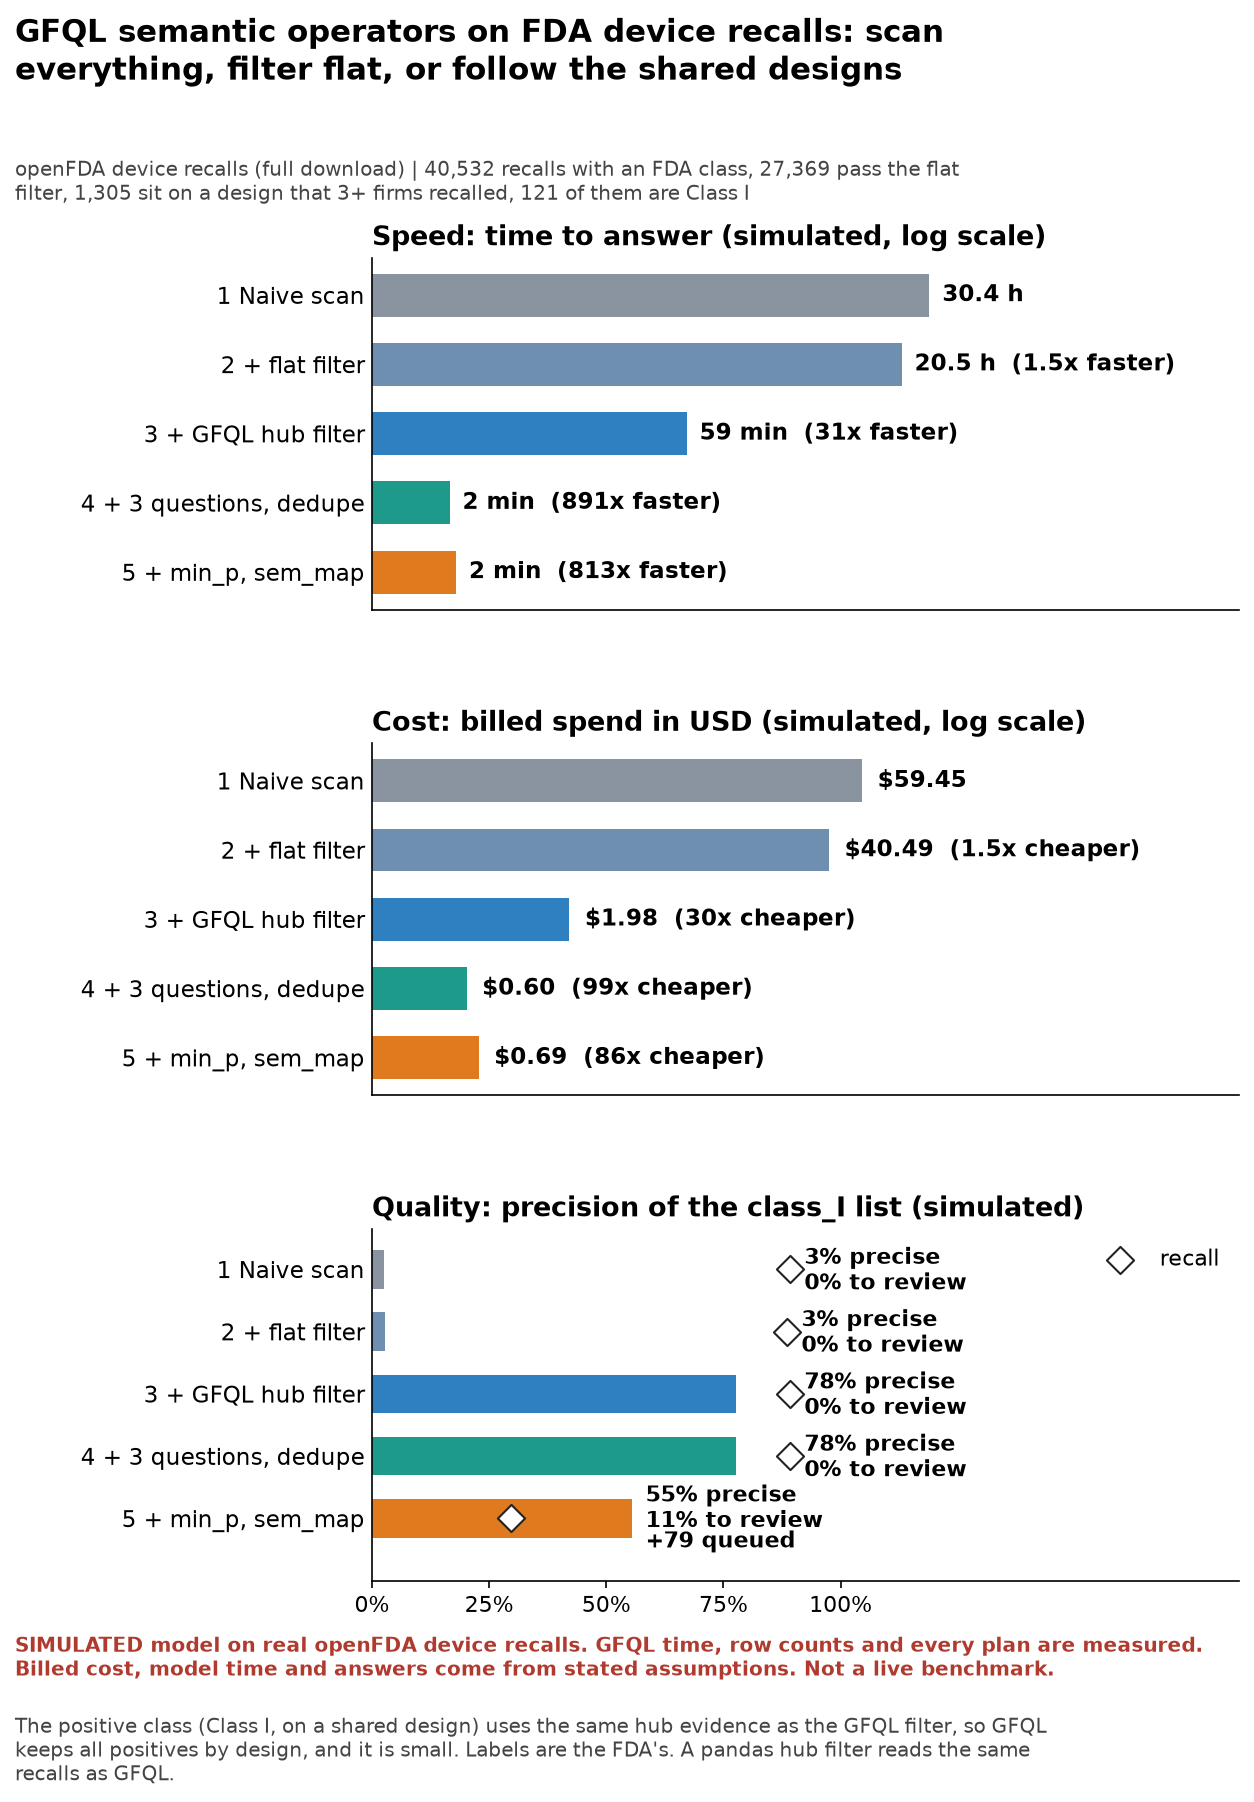

saved gfql_semantic_procurement_chart.png


*SIMULATED model on real openFDA device recalls*

,recalls read,cost vs the step before,time vs the step before
step,,,
1 Naive,40532,NaN,NaN
2 +flat filter,27369,1.468,1.481
3 +GFQL hub filter,1305,20.453,20.972
"4 +3 questions, dedupe",1305,3.301,28.702
5 +min_p +sem_map,1305,0.870,0.911


*SIMULATED model on real openFDA device recalls*

,planned calls,run calls,plan: rows to provider,run: rows to provider,plan: dedupe saves,run: deduped,plan: est. input cost,run: billed cost
stage,,,,,,,,
1 Naive,121596,121596,40532,40532,0,0,46.4564,59.4465
2 +flat filter,82107,82107,27369,27369,0,0,31.7166,40.4879
3 +GFQL hub filter,3915,3915,1305,1305,0,0,1.5615,1.9795
"4 +3 questions, dedupe",595,595,595,595,710,710,0.1863,0.5996
5 +min_p +sem_map,595,595,595,595,710,710,0.1863,0.5996
5 sem_map findings,106,106,106,106,104,104,NaN,0.0000


In [9]:
h.chart()
h.plan_vs_run()

## The chart

The chart above shows time, billed cost and the precision of the `class_I` list for the five stages. The requests and the cost come from the trace of each stage. The time is the modeled time in the default run. The time and cost axes are logarithmic. **How to read the ratios.** Stage 1 is a deliberately plain baseline: one call at a time, no filter. In the step from stage 3 to stage 4, most of the speed gain comes from running 8 calls at once and from asking three questions in one call. The simulator sets the latency of a call, so these gains are modeled and not measured. The step that GFQL adds is stage 3.

**The plan against the run.** Every stage was planned with `explain_sem_decide` (and the findings with `explain_sem_map`) before it ran, and traced with `semantic_trace`. A plan is built by the code that the run uses, so the rows and the calls agree. Two numbers differ in kind: the plan estimates the input cost, and the run reports the cost that the provider billed, which includes output tokens.

## The hub graph

A second GFQL query follows the recalls that need action to their hub designs, and from each design to the other firms that recalled it.

In [10]:
h.incident()

hub query: 73 ms | 1056 nodes, 1861 edges
preview only: set DEMO_PLOT=1 after graphistry.register(...) to open the graph


,nodes
role,
firm,114
hub design,57
recall,885


*SIMULATED model on real openFDA device recalls*

,hub_design,flagged_recalls,firms
0,K063442,33,3
1,K133532,28,7
2,K033737,14,4
3,K112372,11,3
4,K955246,9,11
5,K033326,9,4
6,K191027,8,3
7,K071538,7,3


*SIMULATED model on real openFDA device recalls*

,recall_id,hub_design,hub_firms,verdict,fda_class__p,finding
0,Z-0089-2022,K955246,11,uncertain,0.826,"Transducer, Ultrasonic, Diagnostic: Ultrasound gels and lotions ma..."
1,Z-1651-2021,K133532,7,yes,0.947,"Pump, Infusion: Bezel repair part, not by the original manufacture..."
2,Z-0135-2016,K110151,4,yes,0.941,"System, Nuclear Magnetic Resonance Imagi: In spine clinical workfl..."
3,Z-0407-2016,K033326,4,yes,0.925,"System, X-Ray, Tomography, Computed: During scans with specific pr..."
4,Z-1140-2019,K041949,4,yes,0.850,"System, X-Ray, Angiographic: Additional units have been identified..."
5,Z-1141-2019,K033737,4,yes,0.850,"System, X-Ray, Angiographic: Additional units have been identified..."


*SIMULATED model on real openFDA device recalls*

,device_name,reason_for_recall,fda_class__p
66,"Catheter, Retention Type, Balloon","The catheters are suspected to contain defective sensors; if used,...",0.84989
72,"Catheter, Retention Type, Balloon","The catheters are suspected to contain defective sensors; if used,...",0.84989
67,"Catheter, Retention Type, Balloon","The catheters are suspected to contain defective sensors; if used,...",0.84989
68,"Catheter, Retention Type, Balloon","The catheters are suspected to contain defective sensors; if used,...",0.84989
71,"Catheter, Retention Type, Balloon","The catheters are suspected to contain defective sensors; if used,...",0.84989


In [11]:
h.summary()

SIMULATED model on real openFDA device recalls | openFDA device recalls (full download)
Rows: 40,532 recalls -> 27,369 after the flat filter -> 1,305 after the GFQL hub filter (46 ms for the traversal over the existing hub flag).
The positives are few: 121 Class I recalls on a hub, 23% of them on one design. GFQL keeps all of them by design: the positive class uses the same hub evidence. The flat filter keeps 88. The Class I share is about the same on a hub (9.3%) as off a hub (8.1% for recalls with a 510(k), 10.8% for recalls with none), so the hub narrows what you read and is not a strong sign of severity.
Cost and time fall at stage 3 because GFQL reads fewer recalls than the flat filter ($40.49 and 20.5 h against $1.98 and 59 min). Stage 4 adds the shared call, concurrency and dedupe (54% of its recalls repeat a text). Stage 5 adds findings and a queue, so it costs 15% more than stage 4.
Precision of the class_I list: naive 3%, flat 3%, GFQL 78%, with min_p 55% (min_p lowered it he

## Measure a live model (opt in)

Set `DEMO_LIVE=1` and restart the notebook. The same code then runs with real providers. The run sends recall text to the model provider
and the provider bills you. These limits stay on:

- the decision stages use `budget={"max_cost_usd": 0.50}`. The cap bounds the **estimated input cost** of a stage. It does not bound output, retries or the real bill, so check your provider's usage page. The plan before each stage shows the estimate
- stages 1 to 3 ask about a random sample of 50 recalls each, and stages 4 and 5 about 200. The notebook scales their cost and time to all rows. It does not report the quality of stage 1, because 50 random recalls hold about no positive. The quality of the other stages comes from small samples, so read it as rough
- the `sem_map` findings have no cost estimate. They are capped by request count: one request for each recall that needs action
- the cache pass and the batching table are skipped, because they would send more paid runs
- the chart footer says "Measured with a live model"
- the chat provider and the decisions provider both use `OPENAI_BASE_URL`

Set these variables first. Do not put a key in a notebook.

| variable | meaning |
|---|---|
| `OPENAI_API_KEY` | key for an OpenAI-compatible host |
| `OPENAI_BASE_URL` | optional host URL. Default `https://api.openai.com/v1` |
| `OPENAI_CHAT_MODEL` | model for stages 1 to 3 and for the `sem_map` findings |
| `OPENAI_DECISIONS_MODEL` | model for the decisions endpoint in stages 4 and 5 |
| `PRICE_IN`, `PRICE_CACHED`, `PRICE_OUT` | your prices in USD for one million tokens |

Check your data policy first. These recall texts are public. Your own supplier data is not, and you must not send it to a provider that your
policy does not allow. The same code works on your own tables.

## Appendix: the helper module

`procurement_helpers.py` sits next to this notebook. It holds the openFDA download and parse, the root-cause families, the hub computation, the simulated model (a mock HTTP session that answers in the OpenAI format), the stage runners and the chart. The cell below shows its source.

In [12]:
from IPython.display import Code

Code(filename="procurement_helpers.py", language="python")

# flake8: noqa: F821
"""Helpers for the openFDA device-recall demo (gfql_semantic_procurement.ipynb).

The notebook shows the GFQL and semantic-operator calls. This file holds the plumbing: the openFDA download and parse, the six
root-cause families, the hub-design computation, the simulated model (a calibrated mock HTTP session), the stage runner and the chart.
Call `init()` once, then `from procurement_helpers import *`.
"""


import hashlib
import textwrap
import json
import math
import os
import re
import threading
import time
import warnings
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import graphistry
from graphistry import e_forward, e_reverse, n
from graphistry.compute.predicates.is_in import is_in
from graphistry.compute.semantic import (CallableGenerationProvider, MemorySemanticCache, OpenAIChatProvider, OpenAIDecisionsProvider, ProviderCapabilities,
                                         TokenPrices, bind_providers, explain_sem_decide, explain_sem_map, sem_decide, sem_map, semantic_summary,
                                         semantic_trace, semantic_verdicts)
from IPython.display import Markdown, display


pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)

warnings.filterwarnings("ignore", message="Determining the column names of a LazyFrame")


DEMO_LIVE = os.environ.get("DEMO_LIVE") == "1"
CACHE_DIR = Path("/tmp/openfda-cache")
FILES = {                                              # name -> (URL, SHA-256 of the file that the committed outputs come from)
    "recall": ("https://download.open.fda.gov/device/recall/device-recall-0001-of-0001.json.zip", "722f262bb47ea506c15da1156a1d49e2a759632f5dcdc0be56b69c7b978a8d18"),
    "enforcement": ("https://download.open.fda.gov/device/enforcement/device-enforcement-0001-of-0001.json.zip", "7aef3d29c13214a0df889108282e3e08034bb9ff74270f7648dc9032ea0dfd2f"),
    "classification": ("https://download.open.fda.gov/device/classification/device-classification-0001-of-0001.json.zip", "c2aace26d6f4a37555eaf685557c3cdfe178527be84bc1e69a5d0228bd050325"),
}
HUB_MIN = 3                                            # a design that this many different firms recalled is a hub


def cached_file(name):
    """Path of a downloaded file. A download goes to a temporary name first."""
    url = FILES[name][0]
    path = CACHE_DIR / url.rsplit("/", 1)[1]
    if not path.exists():
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        part = path.with_suffix(".part")
        with urllib.request.urlopen(url, timeout=300) as reply, open(part, "wb") as handle:
            while chunk := reply.read(1 << 20):
                handle.write(chunk)
        part.replace(path)
    return path


def records(path, keep):
    """The records of an openFDA bulk file, with only the fields in `keep`. The file lists one record per block of lines that
    starts with four spaces and an opening brace, so the notebook never holds the whole file in memory."""
    with zipfile.ZipFile(path) as zf, zf.open(zf.infolist()[0]) as raw:
        block = None
        for line in raw:
            if block is None:
                if line == b"    {\n":
                    block = [line]
                continue
            block.append(line)
            if line in (b"    },\n", b"    }\n"):
                record = json.loads(b"".join(block).rstrip().rstrip(b","))
                yield {field: record.get(field) for field in keep}
                block = None


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while chunk := handle.read(1 << 22):
            digest.update(chunk)
    return digest.hexdigest()


def load_fda():
    """Return (recalls, FDA classes, device names, source label). Downloads the files into CACHE_DIR when they are not cached."""
    try:
        paths = {name: cached_file(name) for name in FILES}
        for name